In [7]:
!pip install kagglehub

import kagglehub
import pandas as pd
import os

# Download dataset F1 resmi dari Kaggle
path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# Read file CSV dari folder lokal yang ter-download
results = pd.read_csv(os.path.join(path, 'results.csv'))
races = pd.read_csv(os.path.join(path, 'races.csv'))
drivers = pd.read_csv(os.path.join(path, 'drivers.csv'))
constructors = pd.read_csv(os.path.join(path, 'constructors.csv'))

# Merapikan nama kolom sebelum digabung agar tidak bentrok
races = races.rename(columns={'name': 'race_name'})
constructors = constructors.rename(columns={'name': 'team_name'})

# Merge data
df = results.merge(races[['raceId', 'year', 'race_name']], on='raceId')
df = df.merge(drivers[['driverId', 'driverRef']], on='driverId')
df = df.merge(constructors[['constructorId', 'team_name']], on='constructorId')

# Filter era modern (2010 ke atas)
df_f1 = df[df['year'] >= 2010].copy()

# Tampilkan 5 data teratas
df_f1[['year', 'race_name', 'driverRef', 'team_name', 'grid', 'positionOrder']].head()

Using Colab cache for faster access to the 'formula-1-world-championship-1950-2020' dataset.


,year,race_name,driverRef,team_name,grid,positionOrder
20320,2010,Bahrain Grand Prix,alonso,Ferrari,3,1
20321,2010,Bahrain Grand Prix,massa,Ferrari,2,2
20322,2010,Bahrain Grand Prix,hamilton,McLaren,4,3
20323,2010,Bahrain Grand Prix,vettel,Red Bull,1,4
20324,2010,Bahrain Grand Prix,rosberg,Mercedes,5,5


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Bikin Variabel Target (is_podium): 1 jika finis 1-3, 0 jika > 3
df_f1['is_podium'] = (df_f1['positionOrder'] <= 3).astype(int)

# 2. Fitur yang dipakai (X) & Target (y)
features = ['grid', 'driverRef', 'team_name', 'race_name']
X = df_f1[features]
y = df_f1['is_podium']

# 3. Ubah teks (driver, team, sirkuit) jadi angka pakai One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=['driverRef', 'team_name', 'race_name'], drop_first=True)

# 4. Bagi data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

# 5. Scaling angka posisi grid
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
# Inisialisasi model (menggunakan class_weight='balanced' untuk mengatasi imbalanced data)
models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42)
}

print("=== HASIL EVALUASI PREDIKSI FINIS PODIUM F1 ===\n")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"--- {name} ---")
    print(f"Accuracy: {acc * 100:.2f}%\n")

=== HASIL EVALUASI PREDIKSI FINIS PODIUM F1 ===

--- Logistic Regression ---
Accuracy: 83.07%

--- Decision Tree ---
Accuracy: 86.41%

--- Random Forest ---
Accuracy: 88.04%



In [10]:
# Cek detail Precision, Recall, dan F1-Score dari Random Forest
rf_model = models["Random Forest"]
y_pred_rf = rf_model.predict(X_test_scaled)

print("=== CLASSIFICATION REPORT (RANDOM FOREST) ===")
print(classification_report(y_test, y_pred_rf))

=== CLASSIFICATION REPORT (RANDOM FOREST) ===
              precision    recall  f1-score   support

           0       0.92      0.94      0.93      1105
           1       0.59      0.53      0.56       183

    accuracy                           0.88      1288
   macro avg       0.76      0.73      0.74      1288
weighted avg       0.88      0.88      0.88      1288



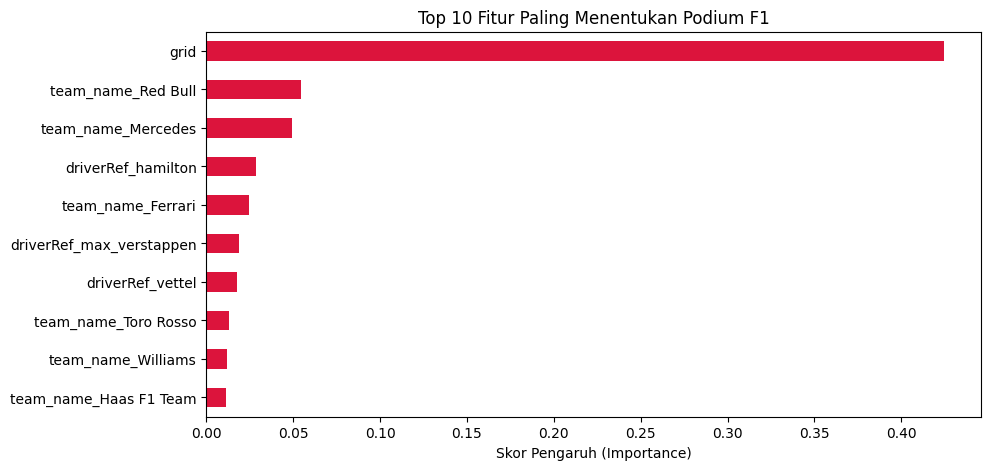

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ambil 10 fitur paling berpengaruh di Random Forest
importance = pd.Series(rf_model.feature_importances_, index=X_encoded.columns)
top_10_features = importance.nlargest(10).sort_values(ascending=True)

# Visualisasi Grafik Batang
plt.figure(figsize=(10, 5))
top_10_features.plot(kind='barh', color='crimson')
plt.title("Top 10 Fitur Paling Menentukan Podium F1")
plt.xlabel("Skor Pengaruh (Importance)")
plt.show()
